# Customer Churn Predictor — Telco Customer Churn

**Business problem:** A telecom company is losing customers every month. We need to (1) find out *why* customers leave, (2) build a model that predicts *who* will leave next, and (3) hand the result to a live Streamlit app.

This notebook follows the 11 steps in the project brief:

1. Load → 2. First look → 3. Clean → 4. EDA → 5. Prepare → 6. Pipeline → 7. Compare models → 8. Focus on recall → 9. Tune → 10. Evaluate → 11. Recommend

**How to run on Google Colab**
1. Upload this `Churn_Project.ipynb` and `telco_churn.csv` to Colab (or just the notebook — the first cell lets you upload the CSV).
2. Runtime → Run all.
3. Read the printed tables and copy the **best model name + best parameters + test recall** into your message back to me — I'll use them to build `app.py`.

Every step has a short explanation written in my own words.

In [1]:
# STEP 1 - LOAD THE DATA
# Imports we need for cleaning, plotting, modelling and evaluation.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_PATH = "telco_churn.csv"
if not os.path.exists(DATA_PATH):
    # Running on Colab without the CSV in the working directory:
    # a file picker will appear - choose telco_churn.csv from your computer.
    from google.colab import files
    print("Please upload telco_churn.csv when the file picker appears...")
    files.upload()

df = pd.read_csv(DATA_PATH)
print("Loaded", DATA_PATH, "->", df.shape[0], "rows and", df.shape[1], "columns")
df.head()

Loaded telco_churn.csv -> 7043 rows and 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Step 2 — First look

Before touching the data I check its shape, types, duplicates and the class balance. This tells me what kind of cleaning is needed and confirms the churn rate (about 26.5%, so classes are imbalanced).

In [2]:
# STEP 2 - FIRST LOOK
print("Shape (rows, columns):", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nDuplicate rows:", df.duplicated().sum())

missing = df.isna().sum()
print("\nMissing values per column:")
print(missing[missing > 0] if missing.sum() else "None")

print("\nChurn counts:")
print(df["Churn"].value_counts())
print("Churn rate: {:.1%}".format((df["Churn"] == "Yes").mean()))

Shape (rows, columns): (7043, 21)

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Duplicate rows: 0

Missing values per column:
None

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn rate: 26.5%


### Step 3 — Clean

`TotalCharges` is stored as text because 11 rows contain a blank space instead of a number. Those 11 customers all have `tenure = 0` — they just joined and have never been billed — so filling their total with 0 is honest and lets us keep the rows.

I also drop `customerID`: it is a unique label, not a predictor. Keeping it would only let a model memorise individuals instead of learning patterns.

In [3]:
# STEP 3 - CLEAN
# Turn TotalCharges text into numbers; blanks become NaN so we can inspect them.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce")

blank_rows = int(df["TotalCharges"].isna().sum())
print("Blank TotalCharges found:", blank_rows)
print("Their tenure values:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())
print("Their Churn values:", df.loc[df["TotalCharges"].isna(), "Churn"].unique())

# New customers with 0 tenure have not been billed yet -> total of 0.
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is an identifier, not a feature.
df = df.drop(columns=["customerID"])

print("\nTotalCharges dtype now:", df["TotalCharges"].dtype)
print("Missing values left:", int(df.isna().sum().sum()))
print("Clean shape:", df.shape)
df.head()

Blank TotalCharges found: 11
Their tenure values: [0]
Their Churn values: ['No']

TotalCharges dtype now: float64
Missing values left: 0
Clean shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Step 4 — EDA (Exploratory Data Analysis)

This is the "why" the managers care about. I group customers by contract, payment method, internet service, tenure band and monthly charge band, and compare each group's churn rate with the overall average (the dashed line).

=== Churn rate by Contract ===
                 mean  size
Contract                   
Month-to-month  0.427  3875
One year        0.113  1473
Two year        0.028  1695

=== Churn rate by Payment Method ===
                            mean  size
PaymentMethod                         
Electronic check           0.453  2365
Mailed check               0.191  1612
Bank transfer (automatic)  0.167  1544
Credit card (automatic)    0.152  1522

=== Churn rate by Internet Service ===
                  mean  size
InternetService             
Fiber optic      0.419  3096
DSL              0.190  2421
No               0.074  1526


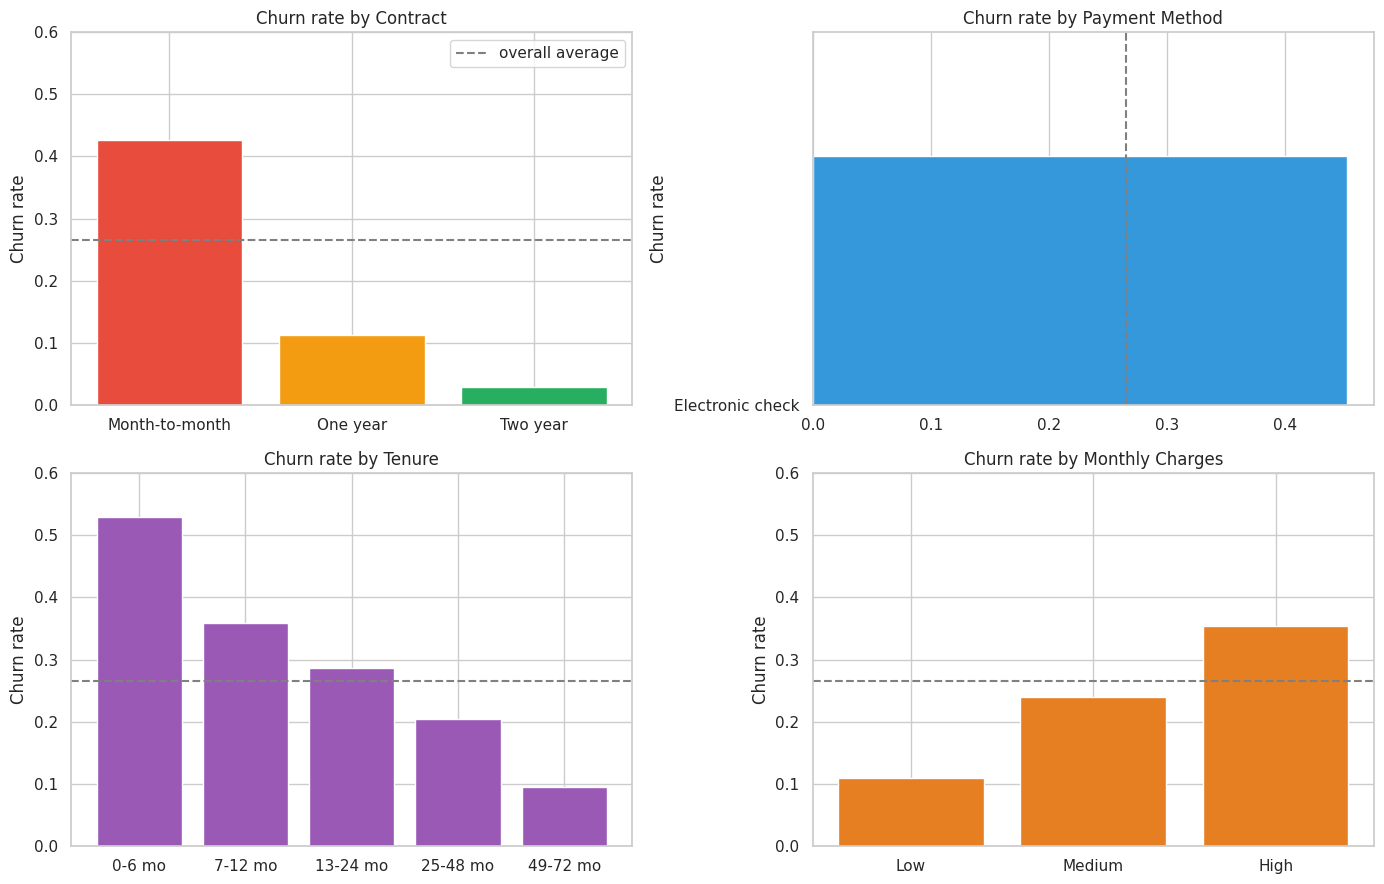

In [4]:
# STEP 4 - EDA: WHY DO CUSTOMERS LEAVE?
churn = (df["Churn"] == "Yes").astype(int)
overall = churn.mean()

def churn_by(col):
    # Average churn rate and group size for each category of `col`.
    return (df.assign(_churn=churn)
              .groupby(col)["_churn"]
              .agg(["mean", "size"])
              .sort_values("mean", ascending=False))

print("=== Churn rate by Contract ===")
print(churn_by("Contract").round(3))
print("\n=== Churn rate by Payment Method ===")
print(churn_by("PaymentMethod").round(3))
print("\n=== Churn rate by Internet Service ===")
print(churn_by("InternetService").round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

tmp = churn_by("Contract")
axes[0, 0].bar(tmp.index, tmp["mean"], color=["#e74c3c", "#f39c12", "#27ae60"])
axes[0, 0].axhline(overall, ls="--", c="gray", label="overall average")
axes[0, 0].set_title("Churn rate by Contract")
axes[0, 0].legend()

tmp = churn_by("PaymentMethod")
axes[0, 1].barh(tmp.index, tmp["mean"], color="#3498db")
axes[0, 1].axvline(overall, ls="--", c="gray")
axes[0, 1].set_title("Churn rate by Payment Method")

tenure_bins = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
                     labels=["0-6 mo", "7-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"])
tmp = df.assign(_churn=churn, _band=tenure_bins).groupby("_band", observed=True)["_churn"].mean()
axes[1, 0].bar(tmp.index.astype(str), tmp.values, color="#9b59b6")
axes[1, 0].axhline(overall, ls="--", c="gray")
axes[1, 0].set_title("Churn rate by Tenure")

charge_bins = pd.cut(df["MonthlyCharges"], bins=[0, 35, 70, 120],
                     labels=["Low", "Medium", "High"])
tmp = df.assign(_churn=churn, _band=charge_bins).groupby("_band", observed=True)["_churn"].mean()
axes[1, 1].bar(tmp.index.astype(str), tmp.values, color="#e67e22")
axes[1, 1].axhline(overall, ls="--", c="gray")
axes[1, 1].set_title("Churn rate by Monthly Charges")

for ax in axes.flat:
    ax.set_ylabel("Churn rate")
    ax.set_ylim(0, 0.6)
plt.tight_layout()
plt.show()

### Step 5 — Prepare the split

I separate features (`X`) from the target (`y`, where 1 = churned) and split 80/20. `stratify=y` keeps the same 26.5% churn ratio in both train and test sets — without it, a random split could give us a misleading test set.

In [5]:
# STEP 5 - PREPARE THE 80/20 SPLIT
X = df.drop(columns=["Churn"])
y = (df["Churn"] == "Yes").astype(int)   # 1 = churned, 0 = stayed

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Churn rate train: {:.1%}".format(y_train.mean()))
print("Churn rate test : {:.1%}".format(y_test.mean()))

Train rows: 5634 | Test rows: 1409
Churn rate train: 26.5%
Churn rate test : 26.5%


### Step 6 — Pipeline

Numbers get standardised (mean 0, standard deviation 1) and categories get one-hot encoded into 0/1 columns. Putting both inside a `Pipeline` means the exact same transformations are applied to training data, test data and future app inputs — no leakage, no mismatch. `handle_unknown="ignore"` lets the app send a category the model never saw without crashing.

In [6]:
# STEP 6 - BUILD THE PREPROCESSING PIPELINE
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

def evaluate(name, clf, X_tr, y_tr, X_te, y_te):
    # Fit a pipeline and return its scores on the held-out test set.
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred),
        "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
    }

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### Step 7 — Compare three algorithms

We train Logistic Regression, a Decision Tree and a Random Forest with their default settings. Accuracy tells us overall correctness, but recall (the share of real churners we catch) is the metric that matters most here.

In [7]:
# STEP 7 - COMPARE MODELS (DEFAULT SETTINGS)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1),
}
rows = [evaluate(name, clf, X_train, y_train, X_test, y_test)
        for name, clf in models.items()]
baseline = pd.DataFrame(rows).set_index("Model").round(3)
baseline

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.806,0.657,0.559,0.604
Decision Tree,0.721,0.475,0.492,0.484
Random Forest,0.786,0.625,0.487,0.547


### Step 8 — Focus on recall

Only 26.5% of customers churn, so a model can look "accurate" by simply predicting that nobody leaves. Passing `class_weight="balanced"` penalises mistakes on the churn class more heavily and usually lifts recall.

A missed churner is a lost customer, so **recall is our decision metric**.

In [8]:
# STEP 8 - CLASS_WEIGHT="BALANCED" AND COMPARE RECALL
balanced_models = {
    "Logistic Regression (balanced)": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree (balanced)": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=100, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1),
}
rows = [evaluate(name, clf, X_train, y_train, X_test, y_test)
        for name, clf in balanced_models.items()]
balanced = pd.DataFrame(rows).set_index("Model").round(3)

comparison = pd.concat([baseline, balanced]).sort_values("Recall", ascending=False)
print(comparison)
BEST_NAME = comparison["Recall"].idxmax()
print("\nBest recall:", BEST_NAME, "->", round(comparison.loc[BEST_NAME, "Recall"], 3))

                                Accuracy  Precision  Recall     F1
Model                                                             
Logistic Regression (balanced)     0.738      0.504   0.783  0.614
Logistic Regression                0.806      0.657   0.559  0.604
Decision Tree                      0.721      0.475   0.492  0.484
Random Forest                      0.786      0.625   0.487  0.547
Decision Tree (balanced)           0.732      0.495   0.487  0.491
Random Forest (balanced)           0.781      0.610   0.481  0.538

Best recall: Logistic Regression (balanced) -> 0.783


### Step 9 — Tune the winner

`GridSearchCV` tries a small grid of settings for the winning model using 5-fold cross-validation, scoring by recall. Cross-validation means the choice isn't decided by one lucky split.

In [9]:
# STEP 9 - GRIDSEARCHCV ON THE BEST MODEL
tune_grid = {
    "Logistic Regression (balanced)": (
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
        {"model__C": [0.01, 0.1, 1, 10]},
    ),
    "Decision Tree (balanced)": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 5, 10]},
    ),
    "Random Forest (balanced)": (
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1),
        {"model__n_estimators": [100, 200], "model__max_depth": [5, 10, None]},
    ),
}
clf, grid = tune_grid[BEST_NAME]
search = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", clf)]),
    grid, scoring="recall", cv=5, n_jobs=1,
)
search.fit(X_train, y_train)
best_model = search.best_estimator_

print("Winning model:", BEST_NAME)
print("Best parameters:", search.best_params_)
print("Best cross-validated recall: {:.3f}".format(search.best_score_))
print("Tuned test recall: {:.3f}".format(recall_score(y_test, best_model.predict(X_test))))

Winning model: Logistic Regression (balanced)
Best parameters: {'model__C': 1}
Best cross-validated recall: 0.804
Tuned test recall: 0.783


### Step 10 — Evaluate on unseen data

The confusion matrix shows the trade-off directly: **false negatives** are churners we missed (the expensive mistake), while **false positives** are loyal customers we might offer an incentive to (a cheap mistake). The classification report gives precision, recall and F1 for both classes.

Confusion matrix (rows = actual, columns = predicted):
[[747 288]
 [ 81 293]]
False negatives (missed churners): 81
False positives (unnecessary offers): 288


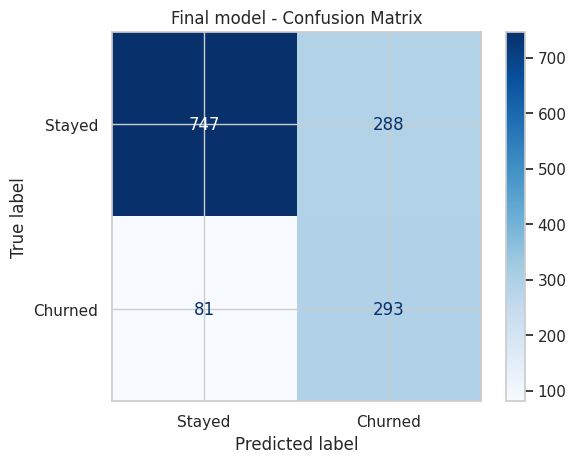


Classification report:
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.842


In [10]:
# STEP 10 - FINAL EVALUATION
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
print("False negatives (missed churners):", cm[1, 0])
print("False positives (unnecessary offers):", cm[0, 1])

ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(
    cmap="Blues", values_format="d")
plt.title("Final model - Confusion Matrix")
plt.show()

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))
print("ROC-AUC: {:.3f}".format(roc_auc_score(y_test, y_prob)))

### Step 11 — Business recommendations

These numbers are computed from our EDA above, so they always match the data. I turn them into actions the retention team can actually take.

In [11]:
# STEP 11 - BUSINESS RECOMMENDATIONS (figures generated from the EDA)
c = churn_by("Contract")
p = churn_by("PaymentMethod")
i = churn_by("InternetService")
band = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
              labels=["0-6 mo", "7-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"])
t = df.assign(_churn=churn, _band=band).groupby("_band", observed=True)["_churn"].mean()
bands = ["0-6 mo", "7-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"]

print("1. MOVE MONTH-TO-MONTH CUSTOMERS ONTO LONGER CONTRACTS")
print("   Month-to-month churn: {:.0%} | One year: {:.0%} | Two year: {:.0%}".format(
    c.loc["Month-to-month", "mean"], c.loc["One year", "mean"], c.loc["Two year", "mean"]))
print("   -> Offer a discount for signing a 1- or 2-year deal.\n")

print("2. ACT IN THE FIRST YEAR")
print("   Churn by tenure: {} ".format(
    " | ".join("{} {:.0%}".format(b, t.loc[b]) for b in bands)))
print("   -> Onboard proactively; check in at months 1, 3 and 6.\n")

print("3. NUDGE ELECTRONIC-CHECK USERS TO AUTOPAY")
print("   Electronic check churn: {:.0%} | Mailed check: {:.0%} | Bank transfer (automatic): {:.0%}".format(
    p.loc["Electronic check", "mean"], p.loc["Mailed check", "mean"],
    p.loc["Bank transfer (automatic)", "mean"]))
print("   -> Give a small bill credit for switching to automatic payment.\n")

print("4. BUNDLE SECURITY / TECH SUPPORT WITH FIBRE")
print("   Fibre churn: {:.0%} | DSL: {:.0%} | No internet: {:.0%}".format(
    i.loc["Fiber optic", "mean"], i.loc["DSL", "mean"], i.loc["No", "mean"]))
print("   -> Free tech-support trial for high-risk fibre customers.")

1. MOVE MONTH-TO-MONTH CUSTOMERS ONTO LONGER CONTRACTS
   Month-to-month churn: 43% | One year: 11% | Two year: 3%
   -> Offer a discount for signing a 1- or 2-year deal.

2. ACT IN THE FIRST YEAR
   Churn by tenure: 0-6 mo 53% | 7-12 mo 36% | 13-24 mo 29% | 25-48 mo 20% | 49-72 mo 10% 
   -> Onboard proactively; check in at months 1, 3 and 6.

3. NUDGE ELECTRONIC-CHECK USERS TO AUTOPAY
   Electronic check churn: 45% | Mailed check: 19% | Bank transfer (automatic): 17%
   -> Give a small bill credit for switching to automatic payment.

4. BUNDLE SECURITY / TECH SUPPORT WITH FIBRE
   Fibre churn: 42% | DSL: 19% | No internet: 7%
   -> Free tech-support trial for high-risk fibre customers.


## Done — what to send back

Please copy these three things from the output above so I can finish the project:

1. **Winning model name** and **best parameters** (Step 9)
2. **Test recall / precision / accuracy** and the **confusion matrix** (Steps 9–10)
3. The four **churn rate figures** printed in Step 11

With that I will build `app.py`, `requirements.txt`, `README.md`, set up the GitHub repo and prepare the Streamlit deployment.